# Minería de Datos: segmentación de productos con clustering
**Caso de estudio:** catálogo de calzado Adidas y Nike  
**Técnicas:** K-Means y clustering jerárquico aglomerativo  
**Herramientas:** Python, pandas, seaborn, scikit-learn y SciPy

## Contexto
Una empresa de investigación de mercados desea identificar grupos de productos con características similares para comprender la oferta de calzado de Adidas y Nike.

## Objetivo
**Aplicar** técnicas de agrupamiento no supervisado mediante K-Means y clustering jerárquico, **evaluar** la calidad de los grupos obtenidos e **interpretar** sus características utilizando análisis exploratorio, métricas y visualizaciones.

**Datos originales:** `df_add_nik.csv`, con 3,268 productos según la descripción del notebook de origen. Variables: `Product Name`, `Product ID`, `Listing Price`, `Sale Price`, `Discount`, `Brand`, `Rating`, `Reviews`.

## 1. Bibliotecas y carga de datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
! ls -la drive/MyDrive/data_add_nik.csv

-rw------- 1 root root 268230 Oct 15 18:17 drive/MyDrive/data_add_nik.csv


In [ ]:
#Cargar datos
ruta = "drive/MyDrive/data_add_nik.csv"
df = pd.read_csv(ruta)
print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (3268, 8)


,Product Name,Product ID,Listing Price,Sale Price,Discount,Brand,Rating,Reviews
0,Women's adidas Originals NMD_Racer Primeknit S...,AH2430,14999,7499,50,Adidas Adidas ORIGINALS,4.8,41
1,Women's adidas Originals Sleek Shoes,G27341,7599,3799,50,Adidas ORIGINALS,3.3,24
2,Women's adidas Swim Puka Slippers,CM0081,999,599,40,Adidas CORE / NEO,2.6,37
3,Women's adidas Sport Inspired Questar Ride Shoes,B44832,6999,3499,50,Adidas CORE / NEO,4.1,35
4,Women's adidas Originals Taekwondo Shoes,D98205,7999,3999,50,Adidas ORIGINALS,3.5,72


## 2. Análisis exploratorio de datos (EDA básico)

In [ ]:
df.info()
print("\nValores faltantes por variable:")
display(df.isna().sum().to_frame("Nulos"))
print("Duplicados completos:", df.duplicated().sum())
print("Valores únicos:")
display(df.nunique().to_frame("Únicos"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3268 entries, 0 to 3267
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Product Name   3268 non-null   object 
 1   Product ID     3268 non-null   object 
 2   Listing Price  3268 non-null   int64  
 3   Sale Price     3268 non-null   int64  
 4   Discount       3268 non-null   int64  
 5   Brand          3268 non-null   object 
 6   Rating         3268 non-null   float64
 7   Reviews        3268 non-null   int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 204.4+ KB

Valores faltantes por variable:


,Nulos
Product Name,0
Product ID,0
Listing Price,0
Sale Price,0
Discount,0
Brand,0
Rating,0
Reviews,0


Duplicados completos: 88
Valores únicos:


,Únicos
Product Name,1531
Product ID,3179
Listing Price,78
Sale Price,227
Discount,6
Brand,5
Rating,32
Reviews,102


In [ ]:
numericas = ["Listing Price", "Sale Price", "Discount", "Rating", "Reviews"]
requeridas = ["Product Name", "Product ID", "Brand"] + numericas
faltantes = [c for c in requeridas if c not in df.columns]
if faltantes:
    raise ValueError(f"Faltan columnas esperadas: {faltantes}")
for col in numericas:
    df[col] = pd.to_numeric(df[col], errors="coerce")
display(df[numericas].describe().T)
print("Productos por marca:")
display(df["Brand"].value_counts().to_frame("Productos"))

,count,mean,std,min,25%,50%,75%,max
Listing Price,3268.0,6868.020196,4724.659386,0.0,4299.0,5999.0,8999.0,29999.0
Sale Price,3268.0,6134.265606,4293.247581,449.0,2999.0,4799.0,7995.0,36500.0
Discount,3268.0,26.875765,22.633487,0.0,0.0,40.0,50.0,60.0
Rating,3268.0,3.242105,1.428856,0.0,2.6,3.5,4.4,5.0
Reviews,3268.0,40.551714,31.543491,0.0,10.0,37.0,68.0,223.0


Productos por marca:


,Productos
Brand,
Adidas CORE / NEO,1111
Adidas ORIGINALS,907
Nike,643
Adidas SPORT PERFORMANCE,606
Adidas Adidas ORIGINALS,1


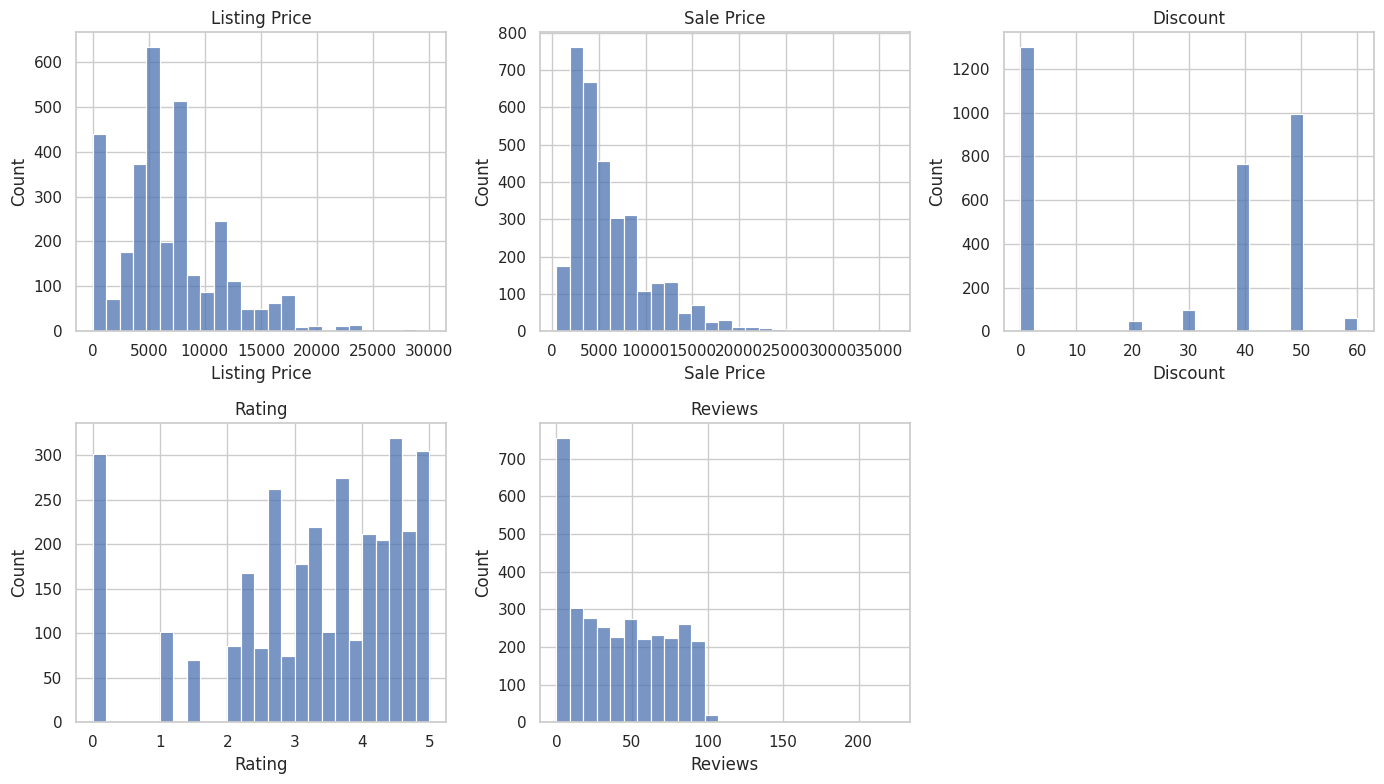

In [ ]:
#Visualizar distribuciones de las variables numericas
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, numericas):
    sns.histplot(data=df, x=col, bins=25, ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(numericas):]: ax.axis("off")
plt.tight_layout(); plt.show()

- Listing Price (Precio de lista): La mayoría de los productos presenta precios inferiores a 10,000, con una concentración importante entre 4,000 y 8,000. La distribución muestra asimetría positiva, con pocos productos de precios elevados.
- Sale Price (Precio de venta): Los precios se concentran principalmente entre 2,000 y 8,000. Presenta una distribución sesgada a la derecha, con algunos productos de precios considerablemente superiores.
- Discount (Descuento): Los descuentos se concentran en valores específicos, principalmente 0 %, 40 % y 50 %. Se observa una proporción importante de productos sin descuento.
- Rating (Calificación): Las calificaciones se concentran principalmente entre 3 y 5, aunque existe una cantidad considerable de productos con calificación 0. Es necesario verificar si este valor representa una calificación real o ausencia de evaluaciones.
- Reviews (Reseñas): Se observa una concentración de productos con pocas reseñas, especialmente cercanas a cero. La distribución presenta asimetría positiva, con algunos productos que acumulan un número mayor de evaluaciones.

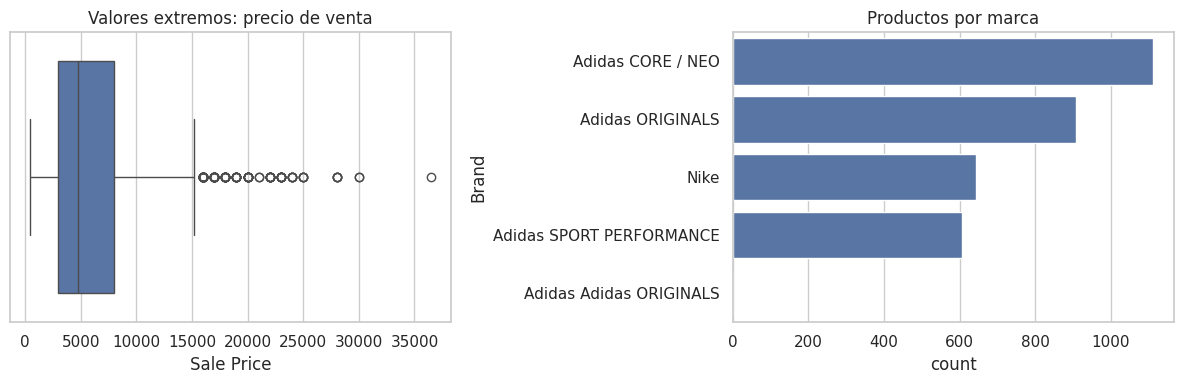

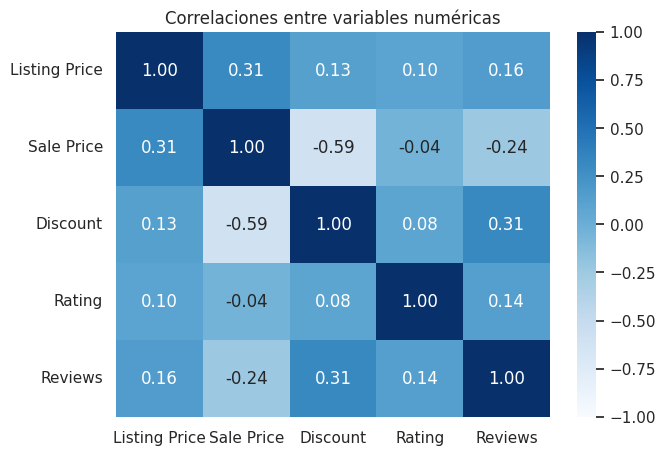

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Sale Price", ax=axes[0]); axes[0].set_title("Valores extremos: precio de venta")
sns.countplot(data=df, y="Brand", order=df["Brand"].value_counts().index, ax=axes[1]); axes[1].set_title("Productos por marca")
plt.tight_layout(); plt.show()
plt.figure(figsize=(7, 5))
sns.heatmap(df[numericas].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1)
plt.title("Correlaciones entre variables numéricas"); plt.show()

Análisis exploratorio: valores atípicos y distribución por marca
* Observaciones:
- Precio de venta (Sale Price): Presenta una dispersión considerable y una distribución asimétrica hacia valores altos. La mayoría de los productos tiene precios inferiores a 8,000.
- Valores atípicos: Se identifican productos con precios superiores a aproximadamente 15,000, algunos cercanos a 36,000. Estos valores pueden influir en los algoritmos basados en distancias.
- Distribución por marca: Adidas CORE / NEO concentra la mayor cantidad de productos, seguida de Adidas ORIGINALS y Nike. Existe un desequilibrio en la representación de las marcas.
* ¿Qué variables serían útiles para agrupar productos? Precio de venta, descuento, calificación y número de reseñas. También puede evaluarse el precio de lista, considerando su posible correlación con el precio de venta.

* Conclusión: Antes del clustering, conviene revisar los valores atípicos, las correlaciones y la escala de las variables para evitar que los precios dominen el cálculo de distancias.

## 3. Limpieza y selección de variables

In [ ]:
# Se identifica un nombre de marca inconsistente.
df["Brand"] = df["Brand"].replace({"Adidas Adidas ORIGINALS": "Adidas ORIGINALS"})

# Sustituir Listing Price = 0 por Sale Price.
mascara = (df["Listing Price"] == 0) & df["Sale Price"].notna()
print("Precios de lista en cero que se corregirán:", mascara.sum())
df.loc[mascara, "Listing Price"] = df.loc[mascara, "Sale Price"]

# Eliminar registros incompletos SOLO en las variables que entrarán al modelo.
# Se mantienen Brand, Reviews, nombre e ID para describir los clústeres después.
variables_modelo = ["Listing Price", "Sale Price", "Discount", "Rating"]
antes = len(df)
df = df.dropna(subset=variables_modelo).copy().reset_index(drop=True)
print("Registros descartados por nulos:", antes - len(df))

# No utilizar Product Name / Product ID: identificadores o texto.
# Brand se reserva para el perfil posterior, evitando definir clústeres por marca.
# Reviews se conserva para el perfil; puede incorporarse tras estudiar su distribución.
X = df[variables_modelo].copy()
X.head()

Precios de lista en cero que se corregirán: 426
Registros descartados por nulos: 0


,Listing Price,Sale Price,Discount,Rating
0,14999,7499,50,4.8
1,7599,3799,50,3.3
2,999,599,40,2.6
3,6999,3499,50,4.1
4,7999,3999,50,3.5


### Estandarizacion de variables

In [ ]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
X_scaled.head()

,Listing Price,Sale Price,Discount,Rating
0,1.509415,0.317928,1.021839,1.090476
1,-0.165605,-0.544022,1.021839,0.040524
2,-1.659542,-1.289493,0.579948,-0.449453
3,-0.301417,-0.613910,1.021839,0.600498
4,-0.075063,-0.497431,1.021839,0.180518


**¿Por qué estandarizar?** K-Means y el agrupamiento jerárquico con distancia euclidiana dependen de las magnitudes.
* Sin escalado, los precios podrían dominar a la calificación y al descuento.
* **Advertencia:** `Listing Price`, `Sale Price` y `Discount` pueden contener información redundante; conviene discutirlo y probar otras selecciones de variables como extensión.

## Distancia euclidiana
Para dos productos representados por dos variables, la distancia euclidiana es:

$$d(A,B) = \sqrt{(x_{A1}-x_{B1})^2 + (x_{A2}-x_{B2})^2}$$

**Ejemplo:** producto $A = (3, 4)$ y producto $B = (6, 8)$. La distancia es $5$ unidades de distancia.

El cálculo detallado utilizando los datos del ejemplo es el siguiente:

$$d(A,B) = \sqrt{(3 - 6)^2 + (4 - 8)^2}$$

$$d(A,B) = \sqrt{(-3)^2 + (-4)^2}$$

$$d(A,B) = \sqrt{9 + 16}$$

$$d(A,B) = \sqrt{25} = 5$$

Donde **5** representa las **unidades de distancia geométrica** (o separación dimensional) entre ambos productos.


* Para agrupar productos reales, la distancia se calcula sobre variables **estandarizadas**.

Distancia euclidiana entre A y B: 5.00


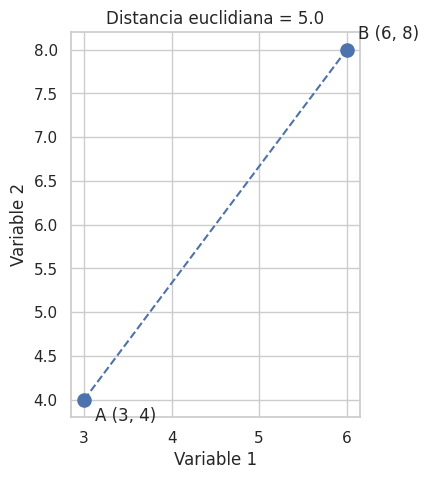

In [ ]:
a = np.array([3., 4.]); b = np.array([6., 8.])
d = np.sqrt(np.sum((a - b)**2))
print(f"Distancia euclidiana entre A y B: {d:.2f}")

fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter([a[0], b[0]], [a[1], b[1]], s=90)
ax.plot([a[0], b[0]], [a[1], b[1]], linestyle="--")
ax.annotate("A (3, 4)", a, xytext=(8, -15), textcoords="offset points")
ax.annotate("B (6, 8)", b, xytext=(8, 8), textcoords="offset points")
ax.set(xlabel="Variable 1", ylabel="Variable 2", title=f"Distancia euclidiana = {d:.1f}")
ax.set_aspect("equal", adjustable="box")

plt.show()

In [ ]:

# Distancia entre dos productos reales, usando todas las variables del modelo.
p0, p1 = X_scaled.iloc[0].to_numpy(), X_scaled.iloc[1].to_numpy()

print("p0",p0)
print("p1",p1)
print("Producto 0:", df.loc[0, "Product Name"])
print("Producto 1:", df.loc[1, "Product Name"])
print("Distancia euclidiana estandarizada:", round(np.linalg.norm(p0 - p1), 3))

p0 [1.50941483 0.31792791 1.02183874 1.09047575]
p1 [-0.16560506 -0.54402243  1.02183874  0.04052444]
Producto 0: Women's adidas Originals NMD_Racer Primeknit Shoes
Producto 1: Women's adidas Originals Sleek Shoes
Distancia euclidiana estandarizada: 2.157


In [ ]:
df.iloc[0]

,0
Product Name,Women's adidas Originals NMD_Racer Primeknit S...
Product ID,AH2430
Listing Price,14999
Sale Price,7499
Discount,50
Brand,Adidas ORIGINALS
Rating,4.8
Reviews,41


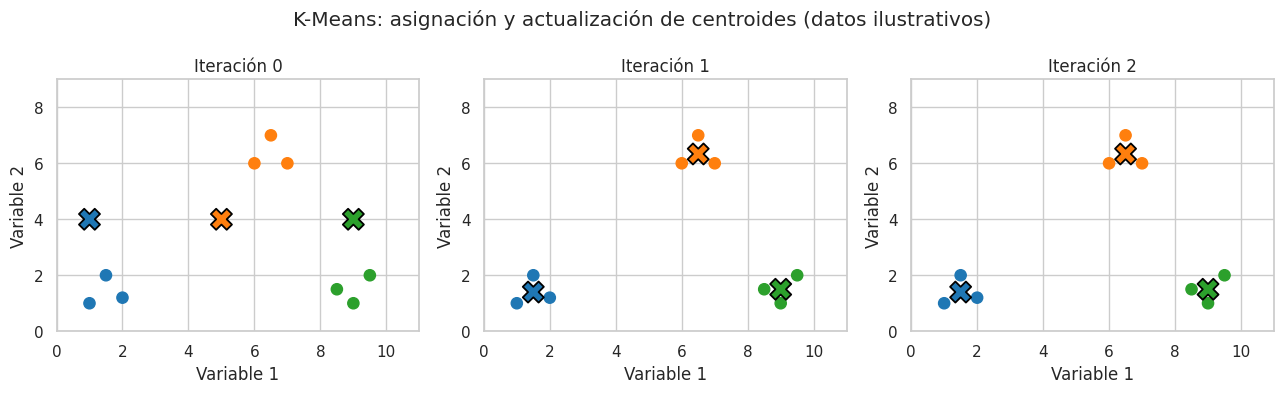

In [ ]:
#Centroides
from sklearn.metrics import pairwise_distances_argmin
puntos_demo = np.array([[1,1],[1.5,2],[2,1.2],[6,6],[7,6],[6.5,7],[9,1],[9.5,2],[8.5,1.5]],dtype=float)
centros = np.array([[1,4],[5,4],[9,4]],dtype=float)

fig, axes = plt.subplots(1,3,figsize=(13,4))
for paso,ax in enumerate(axes):
    grupos = pairwise_distances_argmin(puntos_demo, centros)
    ax.scatter(puntos_demo[:,0],puntos_demo[:,1],c=grupos,cmap='tab10',vmin=0,vmax=9,s=65)
    ax.scatter(centros[:,0],centros[:,1],marker='X',s=230,c=np.arange(3),cmap='tab10',vmin=0,vmax=9,edgecolors='black',linewidths=1.3)
    ax.set(title=f'Iteración {paso}',xlabel='Variable 1',ylabel='Variable 2',xlim=(0,11),ylim=(0,9))
    centros = np.array([puntos_demo[grupos==j].mean(axis=0) if np.any(grupos==j) else centros[j] for j in range(3)])
plt.suptitle('K-Means: asignación y actualización de centroides (datos ilustrativos)')
plt.tight_layout()
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_scaled)


KMeans(n_clusters=3, n_init=10, random_state=42)

In [ ]:
df_km1 = df.copy()
df_km1["Cluster"] = kmeans.labels_
df_km1.head()

,Product Name,Product ID,Listing Price,Sale Price,Discount,Brand,Rating,Reviews,Cluster
0,Women's adidas Originals NMD_Racer Primeknit S...,AH2430,14999,7499,50,Adidas ORIGINALS,4.8,41,0
1,Women's adidas Originals Sleek Shoes,G27341,7599,3799,50,Adidas ORIGINALS,3.3,24,0
2,Women's adidas Swim Puka Slippers,CM0081,999,599,40,Adidas CORE / NEO,2.6,37,0
3,Women's adidas Sport Inspired Questar Ride Shoes,B44832,6999,3499,50,Adidas CORE / NEO,4.1,35,0
4,Women's adidas Originals Taekwondo Shoes,D98205,7999,3999,50,Adidas ORIGINALS,3.5,72,0


In [ ]:
df_km1['Cluster'].value_counts()

,count
Cluster,
0,1832
2,850
1,586


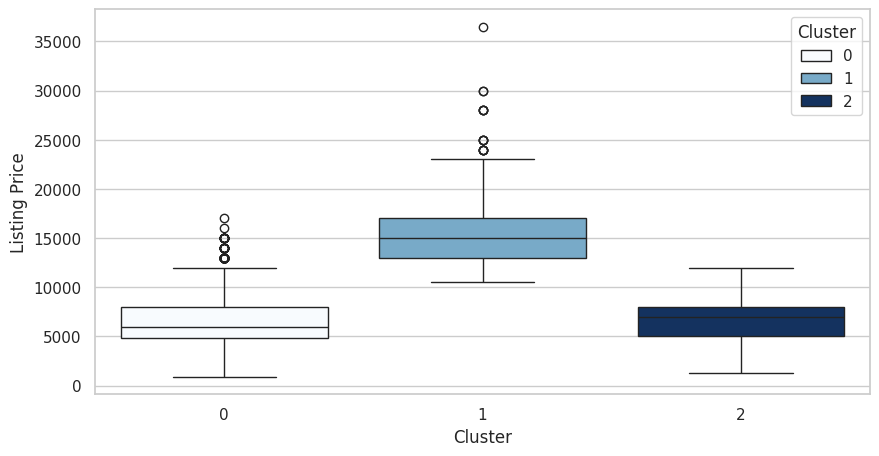

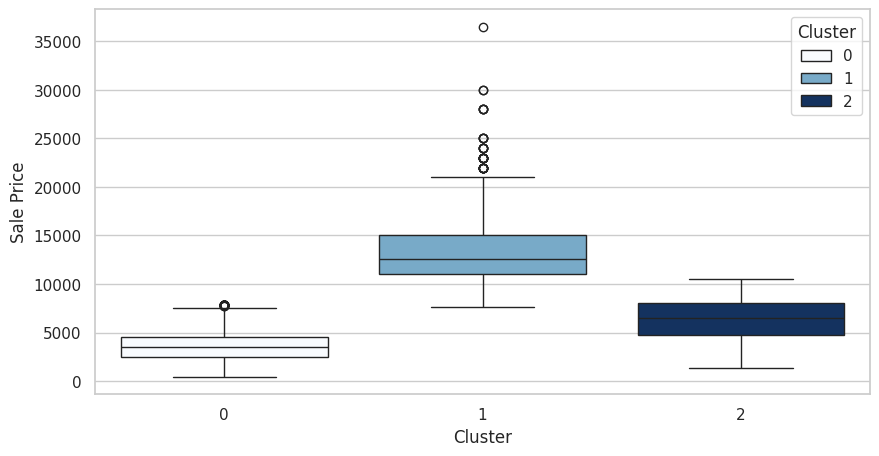

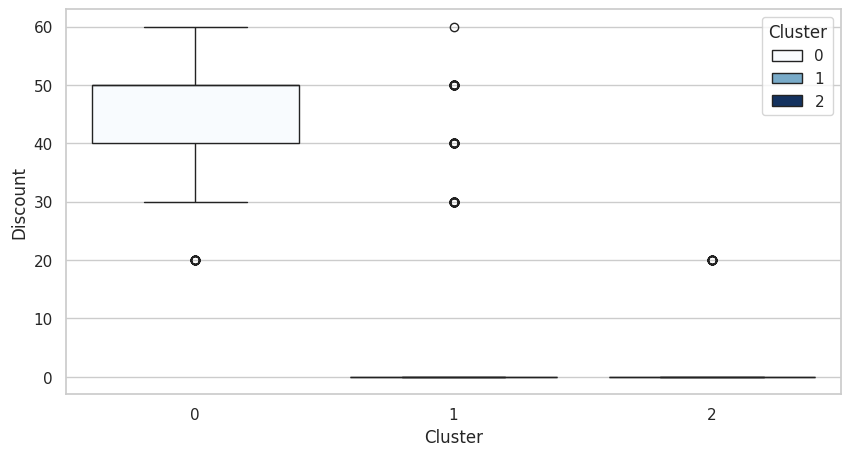

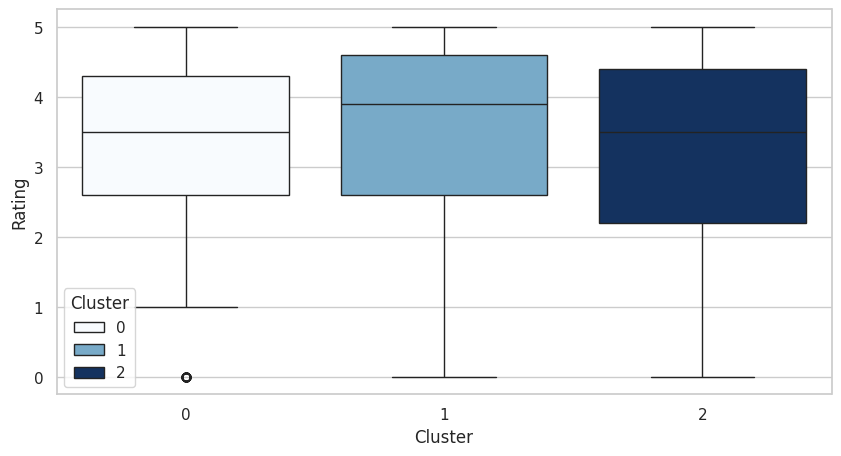

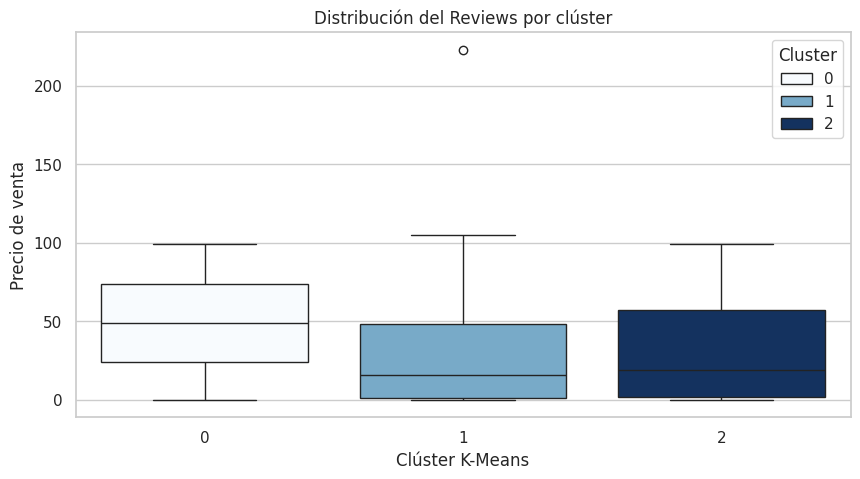

In [ ]:
# Comparar los precios de venta entre clústeres
for v in numericas:
  plt.figure(figsize=(10, 5))

  sns.boxplot(
      data=df_km1,
      x="Cluster",
      y=v,
      hue="Cluster",
      palette="Blues"
  )

plt.title(f"Distribución del {v} por clúster")
plt.xlabel("Clúster K-Means")
plt.ylabel("Precio de venta")
plt.show()

In [ ]:
#Comparacion de varios valores de 'K'
valores_k = range(2, 9)
filas_k = []
for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    etiquetas = modelo.fit_predict(X_scaled)
    print(etiquetas)
    filas_k.append({"k": k, "WCSS": modelo.inertia_,
                    "Silhouette": silhouette_score(X_scaled, etiquetas, sample_size=min(1500, len(X_scaled)), random_state=RANDOM_STATE)})
resultado_k = pd.DataFrame(filas_k)
display(resultado_k.round(3))

[0 0 0 ... 1 1 1]
[0 0 0 ... 2 1 2]
[0 0 0 ... 2 3 1]
[3 1 1 ... 2 0 4]
[3 1 4 ... 0 2 5]
[6 3 1 ... 4 2 5]
[4 6 0 ... 2 7 5]


,k,WCSS,Silhouette
0,2,8216.639,0.384
1,3,6124.521,0.385
2,4,4826.248,0.411
3,5,3985.545,0.391
4,6,3320.231,0.374
5,7,2839.165,0.364
6,8,2562.628,0.364


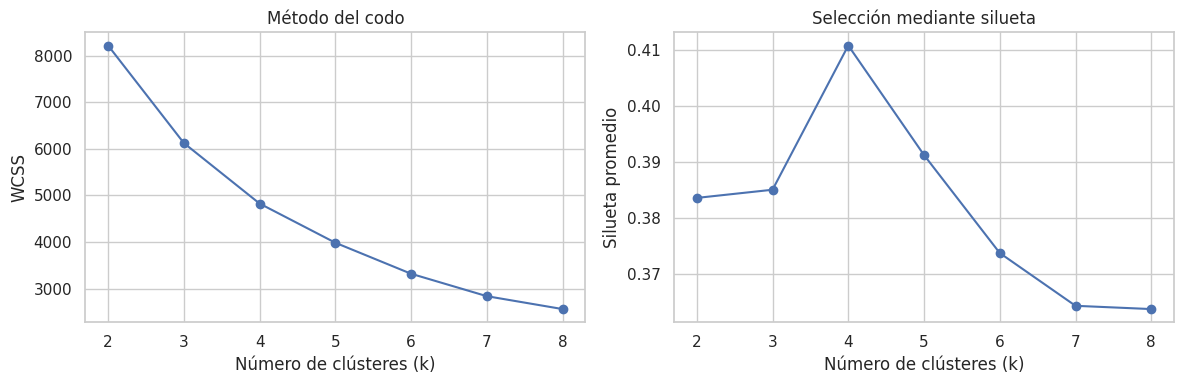

In [ ]:
# Método del codo y Silhouette
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Empaquetar las variables y etiquetas de cada gráfica
metricas = [
    ("WCSS", "WCSS", "Método del codo"),
    ("Silhouette", "Silueta promedio", "Selección mediante silueta")
]

for ax, (columna, ylabel, titulo) in zip(axes, metricas):
    ax.plot(resultado_k["k"], resultado_k[columna], "o-")
    ax.set(xlabel="Número de clústeres (k)", ylabel=ylabel, title=titulo)

plt.tight_layout()
plt.show()


#### Selección del número de clústeres ($K$)

Las gráficas muestran los resultados del **método del codo** y el **coeficiente de silueta** para seleccionar el número óptimo de clústeres en K-Means.

#### **Análisis de Métricas:**

*   **Método del codo:** La inercia (**WCSS**) disminuye conforme aumenta el número de clústeres, pasando de aproximadamente **8,200** con $K=2$ a **2,500** con $K=8$. A partir de $K=4$ o $K=5$, la reducción comienza a ser menos pronunciada, aunque no se identifica un codo geométrico drásticamente definido.
*   **Coeficiente de silueta:** El **valor máximo** se alcanza con $K=4$ (**0.411**), lo que indica una mejor combinación de cohesión interna y separación externa en comparación con los demás valores evaluados. A partir de $K=5$, el coeficiente disminuye progresivamente.

---

#### **💡 Conclusión:**
Se recomienda seleccionar **$K=4$**, principalmente porque presenta el mayor coeficiente de silueta y resulta compatible con la tendencia de estabilización observada en el método del codo.

*Nota:* Debido a que el valor de silueta (0.411) indica una separación moderada, es fundamental realizar un análisis posterior de la distribución y las características de los clústeres obtenidos para validar su relevancia de negocio o investigación.


**Discusión:** el codo puede ser ambiguo. La silueta ayuda a comparar alternativas, pero un valor mayor no garantiza que los segmentos sean útiles para el negocio. Selecciona `k` justificándolo con ambas gráficas y con la interpretabilidad.

In [ ]:
k_elegido = 4
kmeans = KMeans(n_clusters=k_elegido, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_scaled)
df_km = df.copy()
df_km["Cluster"] = kmeans.labels_
display(df.head())
df_km["Cluster"].value_counts()
#

,Product Name,Product ID,Listing Price,Sale Price,Discount,Brand,Rating,Reviews
0,Women's adidas Originals NMD_Racer Primeknit S...,AH2430,14999,7499,50,Adidas ORIGINALS,4.8,41
1,Women's adidas Originals Sleek Shoes,G27341,7599,3799,50,Adidas ORIGINALS,3.3,24
2,Women's adidas Swim Puka Slippers,CM0081,999,599,40,Adidas CORE / NEO,2.6,37
3,Women's adidas Sport Inspired Questar Ride Shoes,B44832,6999,3499,50,Adidas CORE / NEO,4.1,35
4,Women's adidas Originals Taekwondo Shoes,D98205,7999,3999,50,Adidas ORIGINALS,3.5,72


,count
Cluster,
0,1797
2,746
3,402
1,323


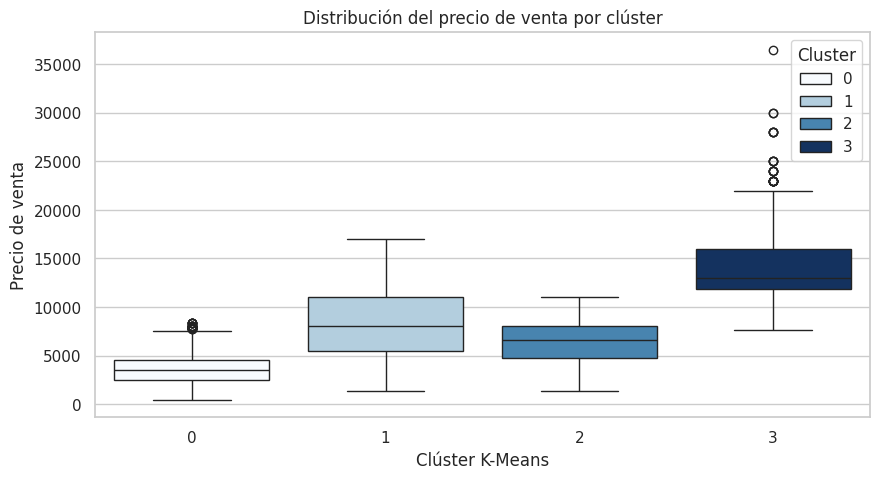

In [ ]:
  # Comparar los precios de venta entre clústeres
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_km,
    x="Cluster",
    y="Sale Price",
    hue="Cluster",
    palette="Blues"
)

plt.title("Distribución del precio de venta por clúster")
plt.xlabel("Clúster K-Means")
plt.ylabel("Precio de venta")
plt.show()

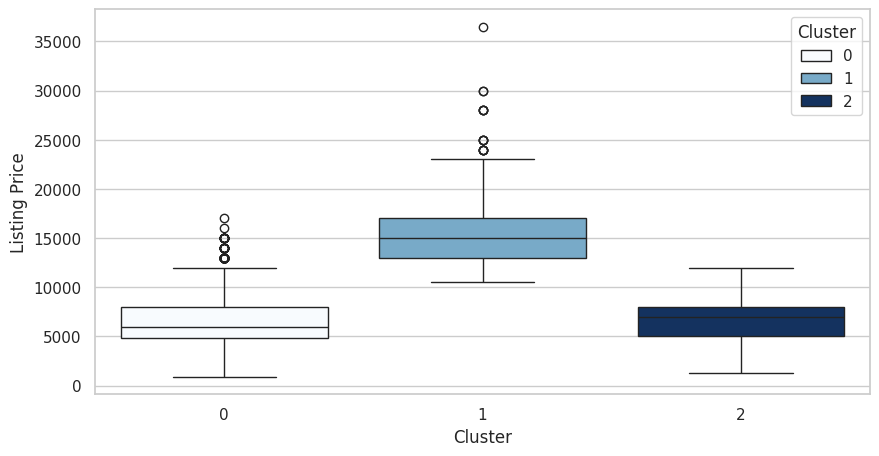

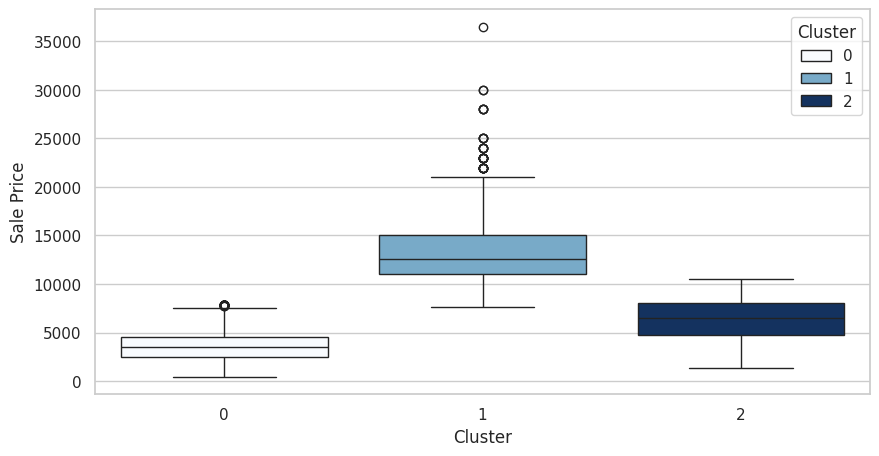

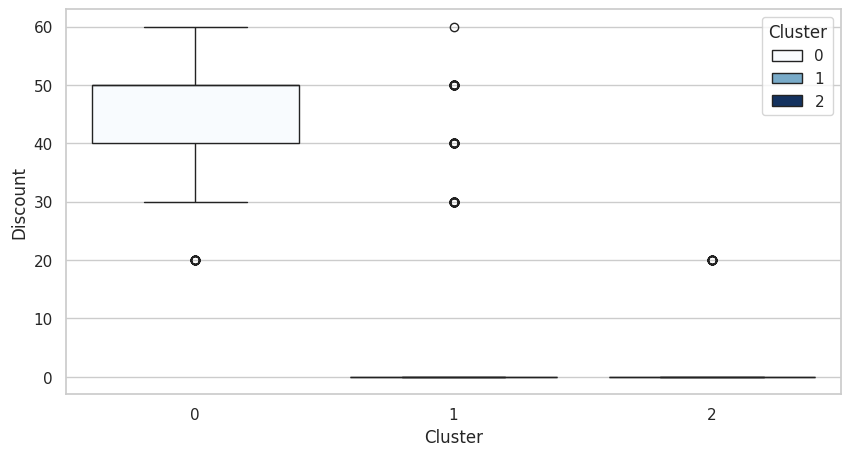

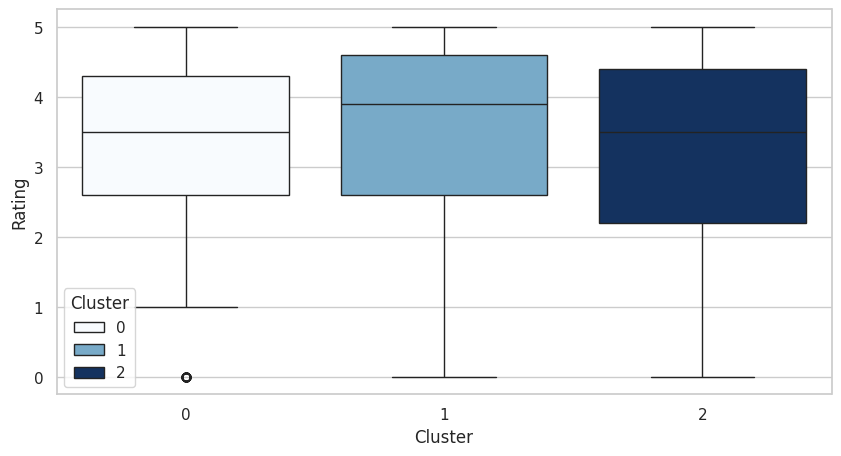

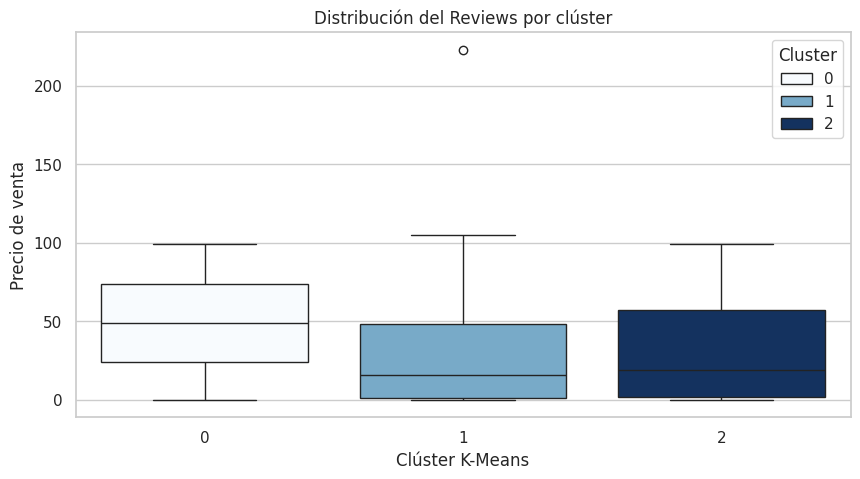

__________________________________________________


In [ ]:
# Comparar los precios de venta entre clústeres
for v in numericas:
  plt.figure(figsize=(10, 5))

  sns.boxplot(
      data=df_km1,
      x="Cluster",
      y=v,
      hue="Cluster",
      palette="Blues"
  )

plt.title(f"Distribución del {v} por clúster")
plt.xlabel("Clúster K-Means")
plt.ylabel("Precio de venta")
plt.show()
print("_"*50)

In [ ]:
#Visualizacion de los centroides
centroides_originales = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                                     columns=X_scaled.columns)
centroides_originales.index.name = "Cluster"
display(centroides_originales.round(2))

,Listing Price,Sale Price,Discount,Rating
Cluster,,,,
0,6813.47,3696.50,45.41,3.39
1,9511.12,8246.88,6.53,0.22
2,7043.17,6649.53,0.70,3.87
3,16553.14,14377.80,8.93,3.84


In [ ]:
#Ajustar pca para reducir dimensiones a componentes principales
pca_cent = PCA(n_components=2)
pca_cent.fit(X_scaled)

prod_pca = pca_cent.transform(X_scaled)
centroides_df = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X_scaled.columns
)

cent_pca = pca_cent.transform(centroides_df)
centroides_df

#

,Listing Price,Sale Price,Discount,Rating
0,-0.343413,-0.567900,0.819213,0.103276
1,0.267212,0.492153,-0.898950,-2.118540
2,-0.291419,0.120036,-1.156813,0.442677
3,1.861201,1.920410,-0.792992,0.419064


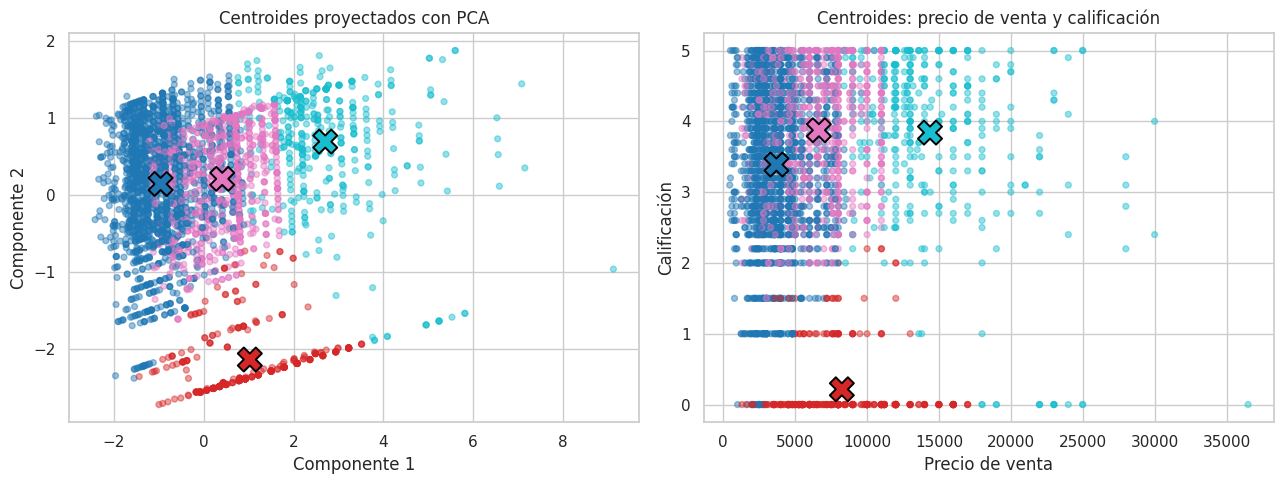

In [ ]:
  #Graficar los centroides con PCA
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

data_plots = [
    (prod_pca, cent_pca, 'Centroides proyectados con PCA', 'Componente 1', 'Componente 2'),
    (df[['Sale Price', 'Rating']].values, centroides_originales[['Sale Price', 'Rating']].values,
     'Centroides: precio de venta y calificación', 'Precio de venta', 'Calificación')
]

for ax, (obs, cents, title, xlab, ylab) in zip(axes, data_plots):
    ax.scatter(obs[:, 0], obs[:, 1], c=df_km['Cluster'], cmap='tab10', s=18, alpha=0.45)

    ax.scatter(cents[:, 0], cents[:, 1], marker='X', c=np.arange(k_elegido), cmap='tab10',
               s=300, edgecolor='black', linewidth=1.4)

    ax.set(title=title, xlabel=xlab, ylabel=ylab)

plt.tight_layout()
plt.show()


### Visualización de clústeres y centroides ($K$-Means)

Las gráficas muestran la distribución de los productos en cuatro segmentos. Los colores representan los clústeres y las **X** indican sus respectivos centroides.

#### **Hallazgos clave:**

* **Proyección con PCA (Izquierda):** Los clústeres ocupan distintas regiones en las dos componentes principales. Existe un solapamiento considerable en la zona central, mientras que el clúster rojo se aísla en valores altos de la Componente 2.
* **Precio de Venta vs. Calificación (Derecha):** Revela la lógica del negocio. El clúster rojo agrupa productos con calificación cercana a cero, el turquesa concentra los precios más elevados y los demás agrupan productos con calificaciones altas y precios moderados.
* **Separación parcial:** El solapamiento visual confirma que los grupos no están drásticamente separados en solo dos dimensiones, lo que valida el coeficiente de silueta moderado (0.411) analizado previamente.

---

#### ** Conclusión:**
El algoritmo identifica con éxito cuatro perfiles comerciales diferenciados por precio y reputación. Para la toma de decisiones, se debe complementar esta visualización con el perfilamiento numérico de cada clúster.

*Nota técnica:* Las **X** en la gráfica derecha representan los centroides reales calculados en el espacio multidimensional. Por ello, no coinciden exactamente con el centro visual del plano bidimensional.


In [ ]:
  # Distancia euclidiana de un producto al centroide asignado (espacio estandarizado)
i_producto=1
c_asignado=int(df_km.loc[i_producto,'Cluster'])
distancia=np.linalg.norm(X_scaled.iloc[i_producto].to_numpy()-kmeans.cluster_centers_[c_asignado])
print(f'Producto 0 → clúster {c_asignado}; distancia al centroide = {distancia:.3f} (unidades estandarizadas)')


Producto 0 → clúster 0; distancia al centroide = 0.278 (unidades estandarizadas)
